# Teks — Klasifikasi dengan TF-IDF (baseline teks paling cepat)
**Kapan dipakai:** klasifikasi teks (sentimen, kategori berita, spam, dll.). Selalu
jalankan ini dulu sebelum model transformer: cepat, dan sering sudah kuat.

**Langkah:** bersihkan teks → TF-IDF (kata 1–2 gram) → model linear → F1 macro.

**Data demo:** SmSA (sentimen Bahasa Indonesia: positive / neutral / negative).

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import make_pipeline, make_union
from sklearn.svm import LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/text/sentiment"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/smsa_train.csv"
TEST_CSV = f"{DATA_FOLDER}/smsa_test.csv"

TEXT_COL = "text"
TARGET = "label"
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train.isna().sum())
train.head()

train: (5148, 3) | test: (1260, 2)
id       0
text     0
label    0
dtype: int64


,id,text,label
0,1,kenapa lumayan enak ? karena ada sushi lain ya...,negative
1,2,berarti staff nya anies yang tidak becus mengu...,negative
2,3,orang cina makanan legendaris sudah lama bange...,negative
3,4,"mental apa ini pak jokowi , bagaimana ini pak ...",negative
4,5,selama iblis binatang ini jadi kapolri jangan ...,negative


## EDA: jumlah per kelas dan panjang teks

label
negative    2000
positive    2000
neutral     1148
Name: count, dtype: int64


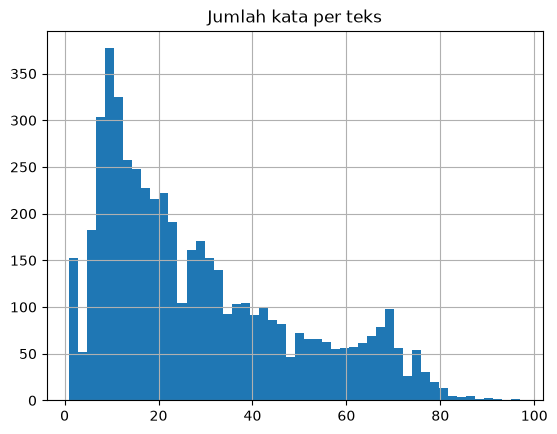

In [4]:
print(train[TARGET].value_counts())
word_counts = train[TEXT_COL].str.split().str.len()
word_counts.hist(bins=50)
plt.title("Jumlah kata per teks")
plt.show()

## Bersihkan teks
Huruf kecil, buang link dan mention, sisakan huruf dan angka saja.

In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|@\w+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return text


print(clean_text("Mantap!! Cek di https://contoh.com @admin, harganya 50rb :)"))

train[TEXT_COL] = train[TEXT_COL].fillna("").apply(clean_text)
test[TEXT_COL] = test[TEXT_COL].fillna("").apply(clean_text)

mantap   cek di      harganya 50rb   


## Split train / validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    train[TEXT_COL], train[TARGET], test_size=0.2, stratify=train[TARGET], random_state=SEED
)

## Model
Pilih SATU vectorizer dan SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada
baris lain.

In [7]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
# vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
#                              sublinear_tf=True)                      # tahan salah ketik
# vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
# vectorizer = make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
#                         TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2))

model = LinearSVC(C=0.5)                          # baseline teks yang kuat
# model = LogisticRegression(C=5, max_iter=2000)  # punya predict_proba
# model = ComplementNB(alpha=0.3)
# model = MultinomialNB(alpha=0.1)
# model = SGDClassifier(loss="modified_huber", random_state=SEED)
# model = RidgeClassifier(alpha=1.0)
# model = CalibratedClassifierCV(LinearSVC(C=0.5))   # LinearSVC + predict_proba
# model = LGBMClassifier(n_estimators=300, verbose=-1, random_state=SEED)

pipe = make_pipeline(vectorizer, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('linearsvc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['negative','neutral','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


## Evaluasi di validasi

F1 macro: 0.8636
              precision    recall  f1-score   support

    negative       0.85      0.86      0.86       400
     neutral       0.86      0.83      0.85       230
    positive       0.88      0.89      0.88       400

    accuracy                           0.87      1030
   macro avg       0.87      0.86      0.86      1030
weighted avg       0.87      0.87      0.87      1030



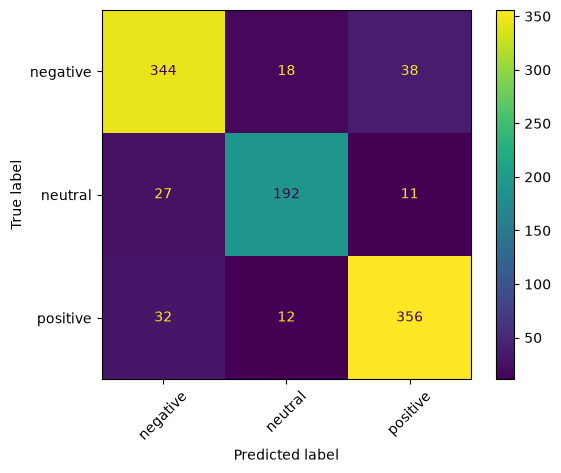

In [8]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
# soal 2 kelas: print("F1:", f1_score(y_val, val_predictions, pos_label="isi_kelas_positif"))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, xticks_rotation=45)
plt.show()

## Latih ulang di semua data + submission

In [9]:
pipe.fit(train[TEXT_COL], train[TARGET])
predictions = pipe.predict(test[TEXT_COL])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,100001,negative
1,100002,negative
2,100003,positive
3,100004,positive
4,100005,negative
